# Labjournaal BM
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name:**  
**Title of the experiment:**  
**Starting date:**  
**Expected enddate:**  
**Partner:**  
**Goal of the experiment:**  
**Research question:**  
**Expectations or Hypothesis:**  
**Desired accuracy:**  




In [19]:
#import necessary libraries
#test
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 

# Preparation
 


**Assignments:**  

**Method:**  
**Theory:**  
**Independent variable:**  
**Dependent variable:**  
**Controlled variablen:**  
**Measurement instruments \& Settings:**  
**Procedure:**  
**Setup(drawing or picture):**  
**Notes:**  
**About accuracy:**  


# Execution

In [20]:
# Measurements, R cuz we read wrong.
with open ('DATA/metingenR.csv') as f:
    metingenR = np.loadtxt(f, delimiter=',', skiprows=1, unpack=True, dtype=float)

#R tabel
Rt = metingenR[0]
u_Rt3 = metingenR[1]
u_Rt5 = metingenR[2]
print(Rt, u_Rt3, u_Rt5)

[1.0e+01 1.0e+02 3.3e+02 3.3e+02 4.7e+02 1.0e+03 4.7e+03 1.0e+04 1.0e+04
 3.3e+04] [1.030e+01 1.002e+02 3.281e+02 3.236e+02 4.700e+02 1.000e+03 4.670e+03
 9.960e+03 1.002e+04 3.297e+04] [1.00290e+01 1.00066e+02 3.28270e+02 3.23760e+02 4.68720e+02 9.98290e+02
 4.67330e+03 9.95580e+03 1.00217e+04 3.29690e+04]


In [21]:
with open('DATA/metingenboltzman.csv') as f:
    metingenboltzman = np.loadtxt(f, delimiter=',', skiprows=1, unpack=True, dtype=float)
# Arrays
V_Bron = metingenboltzman[0]              # V, spanning over bron
V_Weerstand = metingenboltzman[1] / 1000  # V, spanning over R1 (staat in mV in de csv!)

uV_Bron = V_Bron * 0.003 + np.where(V_Bron < 4, 0.001, 0.01)  # V bron, onzekerheid met meter (0.1% + 1 mV of 10 mV)
uV_Weerstand = (V_Weerstand * 0.015 + 0.000006)   # V, onzekerheid spanning over R1 (0.006 mV)

R1 = 10021.7   # 
R2 = 4673.3    
R3 = 328.27    

**Observations:**  
**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**


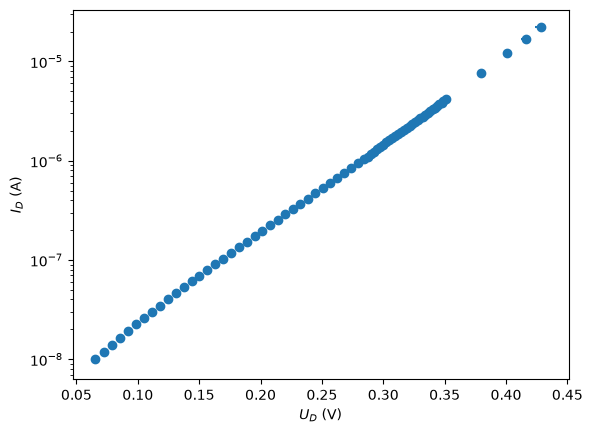

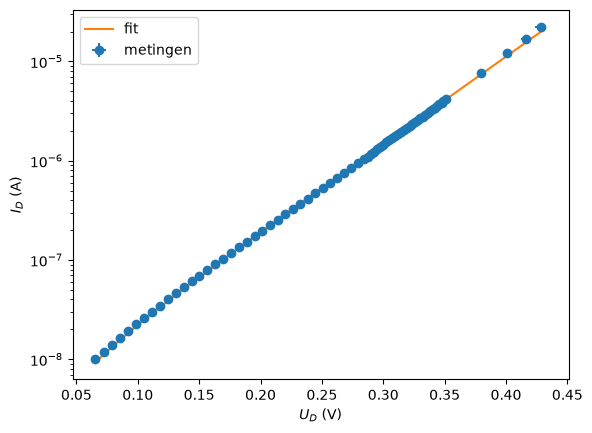

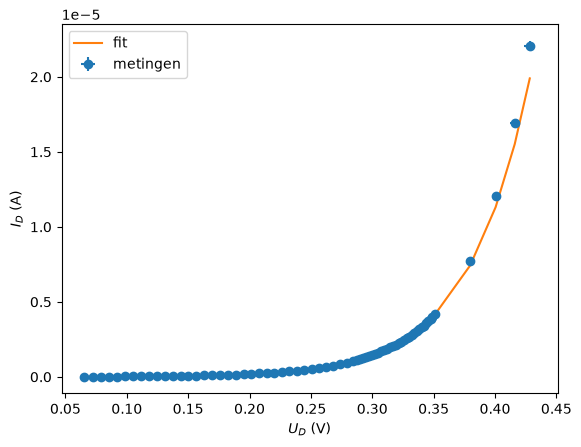

kB = (1.34e-23 +- 6.7e-25) J/K


In [22]:
q = -1.602176634e-19      # C
T, uT = 295.0, 1.0        # K
n, un = 2.0, 0.1

f = R3 / (R2 + R3)           # spanningsdeler: U = f * U_bron
R_th = R2 * R3 / (R2 + R3)   # Thevenin-weerstand van de spanningsdeler

# Bewerkte data
I_D = V_Weerstand / R1
U_D = f * V_Bron - V_Weerstand - I_D * R_th

u_UD = np.sqrt((f * uV_Bron)**2 + ((1 + R_th / R1) * uV_Weerstand)**2)
u_ID = uV_Weerstand / R1     # onzekerheid in R1 verwaarloosd

# Plot 1: metingen (log-schaal)
plt.errorbar(U_D, I_D, xerr=u_UD, yerr=u_ID, fmt="o")
plt.yscale("log")
plt.xlabel("$U_D$ (V)")
plt.ylabel("$I_D$ (A)")
plt.show()

# Fitten
def model(U, I0, b):
    return I0 * np.expm1(b * U)

popt, pcov = curve_fit(model, U_D, I_D, p0=[1e-9, 20], sigma=u_ID, absolute_sigma=True)
I0, b = popt
ub = np.sqrt(pcov[1, 1])

# Plot 2: metingen + fit (log-schaal)
plt.errorbar(U_D, I_D, xerr=u_UD, yerr=u_ID, fmt="o", label="metingen")
plt.plot(U_D, model(U_D, *popt), label="fit")
plt.yscale("log")
plt.xlabel("$U_D$ (V)")
plt.ylabel("$I_D$ (A)")
plt.legend()
plt.show()

# Plot 3: metingen + fit (lineaire schaal)
plt.errorbar(U_D, I_D, xerr=u_UD, yerr=u_ID, fmt="o", label="metingen")
plt.plot(U_D, model(U_D, *popt), label="fit")
plt.xlabel("$U_D$ (V)")
plt.ylabel("$I_D$ (A)")
plt.legend()
plt.show()

# Boltzmann-constante
kB = -q / (b * n * T)
u_kB = kB * np.sqrt((ub / b)**2 + (un / n)**2 + (uT / T)**2)
print(f"kB = ({kB:.2e} +- {u_kB:.1e}) J/K")

In [23]:
#Data processing and analysis:


In [24]:
#Data processing and analysis:


**Describing the pattern in the processed data:**  


In [25]:
#Calculations of e.a. measurement uncertainties, and providing final answers.


**Notes:**  

# Discussion



# Conclusion

# Additional notes, remarks, explanations, thoughts etc